# 11. Model Arena: Comparison, Significance and the Decision Scorecard

**Procurement Intelligence Platform** | Notebook 11 of 13

Every model on the same unseen year (2025). Which is best, is the difference real, which survives shocks, and which should Quayline actually use for each decision?

| | |
|---|---|
| **Inputs** | Cached backtests from notebooks 07 to 10 |
| **Outputs** | Final leaderboard, significance tests, hierarchy check, weighted scorecard, model selection cards |
| **Skills shown** | Model evaluation, statistical testing, decision analysis, communicating trade-offs |

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from p2p.viz.theme import use_matplotlib, BRAND, SERIES, ORIGIN_COLORS, STATUS, shade_shocks
use_matplotlib()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
import json
from p2p.data import panel, company_series
from p2p.forecasting import backtest as bt
from p2p.forecasting.registry import load_arena
from p2p.forecasting.metrics import evaluate, seasonal_naive_scale
from p2p.forecasting.selection import diebold_mariano, ensemble, robustness, scorecard, DEFAULT_WEIGHTS
from p2p.config import TABLES_DIR
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df = panel("pr_lines")
train, _ = bt.train_test(df)
scale = seasonal_naive_scale(train)
val, val_secs = load_arena("inflow", "validation")
test, test_secs = load_arena("inflow", "test")
print(f"Models: {test.model.nunique()} | test forecasts scored: {len(test):,} (12 sections x 10 origins x 12 horizons per model)")

Models: 16 | test forecasts scored: 23,040 (12 sections x 10 origins x 12 horizons per model)


## 1. An ensemble, chosen without looking at 2025

The three best models on the **2024 validation** are averaged with equal weights (point forecasts and quantiles). The members are fixed
before the test year is opened, so the ensemble is a fair contender.

In [3]:
top3 = evaluate(val, scale).model.head(3).tolist()
print("Ensemble members (best 3 on validation):", top3)
test = pd.concat([test, ensemble(test, top3)], ignore_index=True)
test_secs["Ensemble (top 3)"] = sum(test_secs[m] for m in top3)

Ensemble members (best 3 on validation): ['Monte Carlo (structural demand)', 'LightGBM', 'XGBoost']


## 2. Final leaderboard: requisition lines by section, 2025

,model,MASE,WAPE,Bias,Pinball,CRPS,Coverage80,Coverage95,Seconds (10 origins)
0,Monte Carlo (structural demand),0.875,0.346,-0.085,1.415,2.829,0.797,0.938,2.000
1,Ensemble (top 3),0.880,0.348,-0.074,1.392,2.785,0.802,0.948,105.000
2,Random Forest,0.893,0.353,-0.061,1.410,2.820,0.796,0.951,127.000
3,LightGBM,0.899,0.355,-0.074,1.423,2.846,0.799,0.943,56.000
4,N-BEATS,0.910,0.361,-0.134,1.566,3.132,0.792,0.896,47.000
5,XGBoost,0.914,0.361,-0.062,1.438,2.876,0.790,0.945,46.000
6,Chronos-Bolt (zero-shot),0.929,0.367,-0.200,1.512,3.025,0.838,0.941,1.000
7,SARIMAX (Fourier + PM plan),0.933,0.367,-0.100,1.540,3.080,0.858,0.936,69.000
8,Prophet,0.937,0.372,-0.076,1.560,3.120,0.824,0.929,8.000
9,Croston,0.944,0.373,-0.083,1.716,3.431,0.686,0.776,0.000


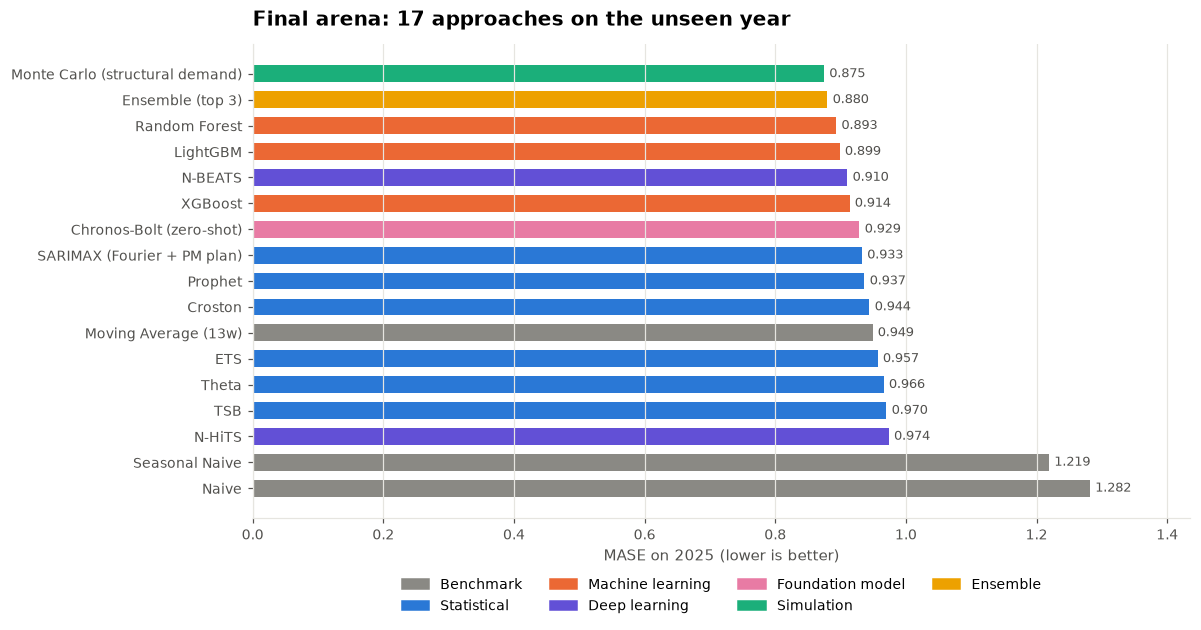

In [4]:
board = evaluate(test, scale)
board["Seconds (10 origins)"] = board.model.map(test_secs).round(0)
display(board)

fig, ax = plt.subplots(figsize=(11, 5.6))
b = board.sort_values("MASE")
family = {"Naive": "Benchmark", "Seasonal Naive": "Benchmark", "Moving Average (13w)": "Benchmark", "ETS": "Statistical", "Theta": "Statistical",
          "SARIMAX (Fourier + PM plan)": "Statistical", "Croston": "Statistical", "TSB": "Statistical", "Prophet": "Statistical",
          "LightGBM": "Machine learning", "XGBoost": "Machine learning", "Random Forest": "Machine learning", "N-HiTS": "Deep learning",
          "N-BEATS": "Deep learning", "Chronos-Bolt (zero-shot)": "Foundation model", "Monte Carlo (structural demand)": "Simulation",
          "Ensemble (top 3)": "Ensemble"}
fam_color = {"Benchmark": BRAND["muted"], "Statistical": SERIES[0], "Machine learning": SERIES[1], "Deep learning": SERIES[6],
             "Foundation model": SERIES[4], "Simulation": SERIES[2], "Ensemble": SERIES[3]}
ax.barh(b.model, b.MASE, color=[fam_color[family[m]] for m in b.model], height=0.65)
for y, v in enumerate(b.MASE):
    ax.text(v + 0.008, y, f"{v:.3f}", va="center", fontsize=8.5, color=BRAND["ink_2"])
ax.invert_yaxis(); ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_xlim(0, b.MASE.max() * 1.12)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f) for f, c in fam_color.items()], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
ax.set_xlabel("MASE on 2025 (lower is better)"); ax.set_title("Final arena: 17 approaches on the unseen year")
plt.show()

**What we see.**

* The **structural Monte Carlo** is the most accurate approach on 2025 (MASE 0.875), just ahead of the **ensemble** of the three
  validation leaders (0.880) and gradient boosting (Random Forest 0.893, LightGBM 0.899). Averaging did not beat its best member here.
* Every serious model beats the benchmarks by a wide margin (seasonal naive 1.22, naive 1.28).
* The spread between the top ten models is small (MASE 0.88 to 0.94). With noisy weekly counts, the question is whether these
  differences are real or luck.

## 3. Are the differences statistically significant?

The Diebold-Mariano test compares the forecast errors of two models week by week, with a correction for the overlap of multi-step
forecasts. A p-value below 0.05 means the difference is unlikely to be luck.

In [5]:
best = board.model.iloc[0]
rows = []
for m in board.model.iloc[1:]:
    stat, p = diebold_mariano(test, best, m)
    rows.append({"compared with": m, "DM statistic": stat, "p-value": p, "verdict": "significantly worse" if p < 0.05 else "not distinguishable"})
dm = pd.DataFrame(rows)
print(f"Reference: {best}")
display(dm)

Reference: Monte Carlo (structural demand)


,compared with,DM statistic,p-value,verdict
0,Ensemble (top 3),-0.308,0.759,not distinguishable
1,Random Forest,-1.115,0.267,not distinguishable
2,LightGBM,-1.302,0.195,not distinguishable
3,N-BEATS,-3.567,0.001,significantly worse
4,XGBoost,-1.905,0.059,not distinguishable
5,Chronos-Bolt (zero-shot),-5.802,0.000,significantly worse
6,SARIMAX (Fourier + PM plan),-2.606,0.010,significantly worse
7,Prophet,-3.127,0.002,significantly worse
8,Croston,-4.607,0.000,significantly worse
9,Moving Average (13w),-4.913,0.000,significantly worse


**What we see.** The simulator is significantly better (p below 0.05) than 12 of the 16 alternatives, including SARIMAX, Prophet, ETS,
Theta, both neural networks and the foundation model. Against the ensemble, Random Forest, LightGBM and XGBoost the difference is **not
statistically significant** on one year of weekly data.

**So what.** Several models are statistically tied at the top. The choice between them should therefore be made on the other criteria
that matter to the business: calibrated uncertainty, robustness, cost and explainability. That is what the scorecard below does.

## 4. Robustness: who breaks under stress?

2025 contains a structural break (the marine contract raised marine demand by 25% from March) and a supplier suspension. Two views:
the worst quarter of each model, and the error on the marine sections after the break.

In [6]:
rb = robustness(test, scale).rename("Worst-quarter MASE")
marine = test[test.unique_id.isin(["SEC10", "SEC11", "SEC12"]) & (test.ds >= "2025-03-03")]
mar = marine.assign(ae=lambda d: (d.y - d.yhat).abs() / d.unique_id.map(scale), b=lambda d: d.yhat - d.y).groupby("model").agg(
    marine_mase=("ae", "mean"), marine_bias=("b", "mean"))
robust = pd.concat([rb, mar], axis=1).sort_values("Worst-quarter MASE")
robust.columns = ["Worst-quarter MASE", "Marine MASE after break", "Marine bias (lines/week)"]
display(robust.round(3))

,Worst-quarter MASE,Marine MASE after break,Marine bias (lines/week)
model,,,
Monte Carlo (structural demand),0.965,1.391,-4.076
N-BEATS,0.966,1.498,-3.872
SARIMAX (Fourier + PM plan),0.977,1.557,-3.423
Ensemble (top 3),0.980,1.444,-3.424
Random Forest,0.997,1.477,-2.703
Prophet,0.998,1.483,-3.881
LightGBM,1.009,1.489,-3.227
Croston,1.011,1.574,-2.558
Chronos-Bolt (zero-shot),1.018,1.560,-5.401


**What we see.** Every model under-forecasts the marine sections after the contract started (negative bias of 2 to 7 lines a week): a
step change cannot be predicted from history alone. The simulator has both the best worst quarter and the lowest marine error after the
break, because it re-estimates each driver's level from the last 26 weeks. Chronos has the largest under-forecast (-5.4 lines a week): it leans on a
past that no longer applies.

**So what.** Known business events (a signed contract) should be fed to the forecast as an adjustment the day they are known. That is a
process recommendation, not a modelling one.

## 5. Do section, business-unit and company forecasts add up? (hierarchical reconciliation)

Forecasting each level separately gives numbers that do not add up. Reconciliation forces coherence; MinT (minimum trace) does it in the
statistically optimal way. Shown with ETS and Theta as base models on the 2025 origins.

In [7]:
from p2p.forecasting.hierarchy import reconcile_backtest, level_accuracy
rec = reconcile_backtest(bt.test_cutoffs())
acc = level_accuracy(rec)
display(acc.round(3))
acc.reset_index().to_parquet(TABLES_DIR / "hierarchy_accuracy.parquet", index=False)

level,Company,Business unit,Section
method,,,
ETS,0.208,0.288,0.375
ETS/BottomUp,0.220,0.288,0.375
ETS/MinTrace_method-mint_shrink,0.211,0.285,0.376
Theta,0.169,0.286,0.384
Theta/BottomUp,0.191,0.281,0.384
Theta/MinTrace_method-mint_shrink,0.165,0.273,0.381


**What we see.** Errors shrink as we move up the hierarchy (about 38% WAPE for sections, 28% for business units, 17 to 21% for the
company): aggregation cancels part of the noise. Simply adding up section forecasts (BottomUp) is worse at company level than forecasting
the company directly. **MinT reconciliation** gets the best of both: with Theta it gives the lowest error at company level (16.5%) and at
business-unit level (27.3%), and all levels add up, which is what a planning meeting needs: one set of numbers.

## 6. The decision scorecard

Accuracy alone does not choose a production model. The scorecard scores every model from 0 to 100 on six criteria and combines them with
weights agreed with the stakeholders:

| Criterion | Weight | Measured by |
|---|---|---|
| Accuracy | 40% | MASE on 2025 |
| Uncertainty | 20% | CRPS and distance of the 80% coverage from 0.80 |
| Robustness | 15% | Worst-quarter MASE |
| Explainability | 10% | Expert rating 1 to 5 (can a planner understand why?) |
| Cost | 10% | Compute time for the backtest (log scale) |
| Maintainability | 5% | Expert rating 1 to 5 (dependencies, retraining effort, skills needed) |

The expert ratings are recorded in `src/p2p/forecasting/selection.py` with the reasoning: a structural simulation and ETS are easy to
explain; gradient boosting is explainable with SHAP; neural networks and foundation models are hard to explain.

In [8]:
sc = scorecard(test, scale, test_secs)
display(sc.round(2))
sc.reset_index(names="model").to_parquet(TABLES_DIR / "scorecard.parquet", index=False)

,MASE,CRPS,Coverage80,WorstQuarterMASE,Seconds,Accuracy,Uncertainty,Robustness,Explainability,Cost,Maintainability,Weighted score
model,,,,,,,,,,,,
Monte Carlo (structural demand),0.870,2.830,0.800,0.960,1.890,100.000,98.220,100.000,100.000,79.350,50.000,95.080
Prophet,0.940,3.120,0.820,1.000,8.490,84.800,82.590,93.070,75.000,54.500,75.000,81.100
LightGBM,0.900,2.850,0.800,1.010,56.390,94.130,98.190,90.590,50.000,16.860,50.000,80.070
Moving Average (13w),0.950,3.420,0.690,1.030,0.080,81.770,44.470,85.960,100.000,100.000,100.000,79.500
Random Forest,0.890,2.820,0.800,1.000,127.480,95.430,98.050,93.140,50.000,0.000,50.000,79.250
ETS,0.960,3.200,0.870,1.060,1.100,79.840,66.800,79.340,75.000,86.080,100.000,78.310
Ensemble (top 3),0.880,2.780,0.800,0.980,104.520,98.710,99.770,96.760,25.000,4.120,25.000,78.120
Croston,0.940,3.430,0.690,1.010,0.100,82.910,44.060,90.300,75.000,99.550,100.000,77.980
XGBoost,0.910,2.880,0.790,1.030,46.240,90.410,94.350,86.540,50.000,20.930,50.000,77.610


In [9]:
weightings = {
    "Default (stakeholder weights)": DEFAULT_WEIGHTS,
    "Accuracy only": {"Accuracy": 1, "Uncertainty": 0, "Robustness": 0, "Explainability": 0, "Cost": 0, "Maintainability": 0},
    "Risk manager (uncertainty and robustness)": {"Accuracy": .25, "Uncertainty": .35, "Robustness": .30, "Explainability": .05, "Cost": .025, "Maintainability": .025},
    "Lean IT team (cost and maintainability)": {"Accuracy": .3, "Uncertainty": .1, "Robustness": .1, "Explainability": .1, "Cost": .2, "Maintainability": .2},
    "Audit and regulators (explainability)": {"Accuracy": .3, "Uncertainty": .1, "Robustness": .1, "Explainability": .4, "Cost": .05, "Maintainability": .05},
}
sens = pd.DataFrame({k: scorecard(test, scale, test_secs, w)["Weighted score"].rank(ascending=False).astype(int) for k, w in weightings.items()})
display(sens.sort_values("Default (stakeholder weights)").head(8))

,Default (stakeholder weights),Accuracy only,Risk manager (uncertainty and robustness),Lean IT team (cost and maintainability),Audit and regulators (explainability)
model,,,,,
Monte Carlo (structural demand),1,1,1,3,1
Prophet,2,9,6,7,3
LightGBM,3,4,4,10,9
Moving Average (13w),4,11,13,1,2
Random Forest,5,3,3,12,10
ETS,6,12,11,5,5
Ensemble (top 3),7,2,2,14,13
Croston,8,10,12,2,4


**What we see.** With the default weights the **structural Monte Carlo** ranks first: it is the most accurate, the best calibrated, the
most robust, fast and easy to explain ("this many breakdowns, this many planned services, the MRP run and a project risk"). It stays first
under four of the five weightings; a cost-driven IT view ranks it third behind the moving average and Croston, which cost nothing but are
less accurate. The ensemble ranks second on accuracy alone but drops to seventh once cost and explainability count. The dashboard lets
users move these weights and see the ranking change.

## 7. Model selection cards

The final recommendation, one card per planning decision:

In [10]:
cards = [
    {"use_case": "Weekly requisition demand by section", "recommended": "Monte Carlo (structural demand)",
     "keywords": ["section", "weekly", "demand", "requisition", "workload", "buyer"],
     "why": "Best single model on 2024 and 2025, best calibrated intervals, runs in seconds and is explained by the demand drivers.",
     "evidence": f"Test MASE {board.set_index('model').loc['Monte Carlo (structural demand)', 'MASE']:.3f}; 80% coverage "
                 f"{board.set_index('model').loc['Monte Carlo (structural demand)', 'Coverage80']:.2f}. Not significantly different from the ensemble.",
     "fallback": "LightGBM (global model with SHAP explanations)"},
    {"use_case": "Company and business-unit totals for budgeting", "recommended": "Theta reconciled with MinT",
     "keywords": ["company", "business unit", "budget", "total", "hierarchy", "consistent"],
     "why": "Forecasts at every level add up, and MinT gives the lowest error at company and business-unit level.",
     "evidence": "Company WAPE 16.5% (MinT) against 19.1% (sum of sections) and 16.9% (Theta at company level only).",
     "fallback": "Ensemble (top 3) summed to totals"},
    {"use_case": "Weekly cash-out forecast for Finance", "recommended": "Monte Carlo (process)",
     "keywords": ["cash", "payment", "finance", "liquidity", "downpayment", "cash-out", "cash out"],
     "why": "Knows which POs are about to be delivered and which downpayments are pending; best accuracy on 2025.",
     "evidence": "Test MASE 0.70 against 0.76 for the best statistical model (ETS).", "fallback": "ETS"},
    {"use_case": "Open backlog total for the next quarter", "recommended": "Theta",
     "keywords": ["backlog", "open lines", "stock", "open backlog"],
     "why": "The backlog is a slow-moving stock: a simple model is the most accurate (WAPE 3.5%).",
     "evidence": "Test MASE 0.42; the process simulator reaches 0.54 but adds what-if capability.", "fallback": "Monte Carlo (process) for scenarios"},
    {"use_case": "What-if decisions (policies, sourcing, capacity, FX)", "recommended": "Monte Carlo (process)",
     "keywords": ["what-if", "what if", "scenario", "decision", "policy", "simulate", "sourcing"],
     "why": "The only approach that represents the process stages a decision changes and propagates the effect to backlog and cash.",
     "evidence": "Backtested on backlog and cash (notebook 10); six management scenarios quantified.", "fallback": "None"},
    {"use_case": "New section or site with little history", "recommended": "Chronos-Bolt (zero-shot)",
     "keywords": ["new", "cold start", "little history", "no history", "new site"],
     "why": "Needs no training data and matches SARIMAX accuracy; adjust for known growth because it under-forecasts trends.",
     "evidence": "Validation MASE 0.767 without any training on Quayline data.", "fallback": "Moving average with a manual trend"},
    {"use_case": "Arrival date of a specific purchase order", "recommended": "Survival model (log-normal AFT)",
     "keywords": ["arrive", "arrival", "eta", "when will", "lead time", "po", "purchase order"],
     "why": "Handles open orders correctly as censored observations; validated against what actually happened after the extraction date.",
     "evidence": "See notebook 12.", "fallback": "Monte Carlo (process) before the PO is approved"},
]
(TABLES_DIR / "selection_cards.json").write_text(json.dumps(cards, indent=2))
display(pd.DataFrame(cards)[["use_case", "recommended", "why", "fallback"]])

# exports for the dashboard
lead = []
for arena in ["inflow", "open_lines", "cash_out_usd"]:
    for split in ["validation", "test"]:
        fc_, secs_ = load_arena(arena, split)
        sc_ = scale if arena == "inflow" else seasonal_naive_scale(bt.train_test(company_series(arena))[0])
        if arena == "inflow" and split == "test":
            fc_ = test
            secs_ = test_secs
        e = evaluate(fc_, sc_)
        e["seconds"] = e.model.map(secs_)
        lead.append(e.assign(arena=arena, split=split))
pd.concat(lead).to_parquet(TABLES_DIR / "arena_leaderboard.parquet", index=False)
company_tests = [load_arena(a, "test")[0].assign(arena=a) for a in ["open_lines", "cash_out_usd"]]
pd.concat([test.assign(arena="inflow")] + company_tests, ignore_index=True).to_parquet(TABLES_DIR / "arena_forecasts_test.parquet", index=False)
print("Exported leaderboard, forecasts, scorecard and selection cards to reports/tables/")

,use_case,recommended,why,fallback
0,Weekly requisition demand by section,Monte Carlo (structural demand),"Best single model on 2024 and 2025, best calibrated intervals, runs in seconds and is explained by the demand drivers.",LightGBM (global model with SHAP explanations)
1,Company and business-unit totals for budgeting,Theta reconciled with MinT,"Forecasts at every level add up, and MinT gives the lowest error at company and business-unit level.",Ensemble (top 3) summed to totals
2,Weekly cash-out forecast for Finance,Monte Carlo (process),Knows which POs are about to be delivered and which downpayments are pending; best accuracy on 2025.,ETS
3,Open backlog total for the next quarter,Theta,The backlog is a slow-moving stock: a simple model is the most accurate (WAPE 3.5%).,Monte Carlo (process) for scenarios
4,"What-if decisions (policies, sourcing, capacity, FX)",Monte Carlo (process),The only approach that represents the process stages a decision changes and propagates the effect to backlog and cash.,None
5,New section or site with little history,Chronos-Bolt (zero-shot),Needs no training data and matches SARIMAX accuracy; adjust for known growth because it under-forecasts trends.,Moving average with a manual trend
6,Arrival date of a specific purchase order,Survival model (log-normal AFT),Handles open orders correctly as censored observations; validated against what actually happened after the extractio...,Monte Carlo (process) before the PO is approved


Exported leaderboard, forecasts, scorecard and selection cards to reports/tables/


## 8. Summary

* Out of 17 approaches, the **structural simulation** is the most accurate on the unseen year, with **gradient boosting** and the
  **ensemble** in a statistically tied top group; all of them beat the benchmarks clearly.
* **No single model wins everything.** Demand, cash, backlog, what-if and arrival dates each have a different best tool.
* The **decision scorecard** makes the trade-off between accuracy, uncertainty, robustness, cost and explainability explicit and
  adjustable, so the choice is a business decision, not a data-science preference.

**Next:** notebook 12 answers the most frequent operational question: when will this purchase order arrive?